In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df_car = pd.read_csv('car_fuel_efficiency_2026.csv')

In [19]:
df_car_lr = df_car[[ 'engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']].copy()

df_car_lr.head(2)

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3


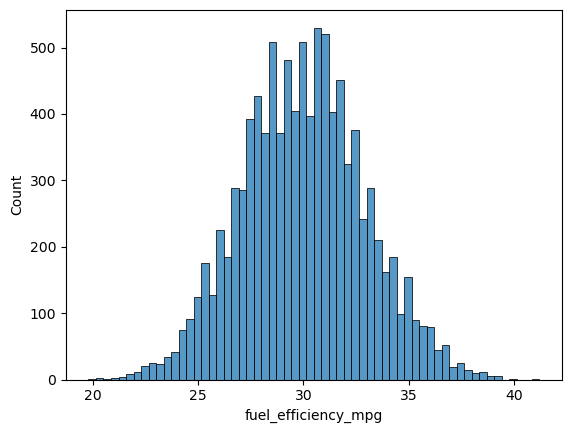

In [20]:
sns.histplot(df_car_lr.fuel_efficiency_mpg)
plt.show()

<font size="5"><b><u> Question 1. There's one column with missing values. What is it? </u></b></font><br>

In [21]:
df_car_lr.isnull().sum()[df_car.isnull().sum() > 0]

horsepower    877
dtype: int64

<font size="5"><b><u> Question 2. What's the median (50% percentile) for variable 'horsepower'? </u></b></font><br>

In [22]:
df_car_lr['horsepower'].median()

254.0

<font size="5"><b><u> Question 3. Which option gives better RMSE? </u></b></font><br>

In [35]:
n = len(df_car_lr)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df_car_lr.iloc[idx[:n_train]]
df_val = df_car_lr.iloc[idx[n_train:n_train + n_val]]
df_test = df_car_lr.iloc[idx[n_train + n_val:]]

In [36]:
target = 'fuel_efficiency_mpg'
features = ['engine_displacement','horsepower','vehicle_weight','model_year']

y_train = df_train[target].to_numpy()
y_val = df_val[target].to_numpy()

In [37]:
def linear_regression(X, y):
    X = np.column_stack([np.ones(len(X)), X])
    w = np.linalg.lstsq(X, y, rcond=None)[0]
    return w[0], w[1:]

In [38]:
def rmse(y, y_pred):
    return np.sqrt(np.mean((y - y_pred) ** 2))

In [42]:
train_means = df_train[features].mean()

scores = {}

for option, fill_value in [('zero', 0), ('mean', train_means)]:
    X_train = df_train[features].fillna(fill_value).to_numpy()
    X_val = df_val[features].fillna(fill_value).to_numpy()

    w0, w = linear_regression(X_train, y_train)
    y_pred = w0 + X_val @ w

    scores[option] = rmse(y_val, y_pred)
    print(f'{option}: {round(scores[option], 3)}')

if round(scores['zero'], 3) == round(scores['mean'], 3):
    print('No Real difference')
else:
    print(f'Better option: {min(scores, key=scores.get)}')

zero: 2.205
mean: 2.202
Better option: mean


<font size="5"><b><u> Question 4. Which r gives the best RMSE? </u></b></font><br>

In [43]:
def linear_regression_reg(X, y, r=0.0):
    X = np.column_stack([np.ones(len(X)), X])

    XTX = X.T @ X
    XTX = XTX + r * np.eye(XTX.shape[0])
    w = np.linalg.solve(XTX, X.T @ y)

    return w[0], w[1:]

In [44]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = linear_regression_reg(X_train, y_train, r)
    y_pred = w0 + X_val @ w

    scores[r] = rmse(y_val, y_pred)
    print(f'r = {r}: RMSE = {round(scores[r], 4)}')

best_r = min(scores, key=scores.get)
print(f'\nBest r: {best_r}')
print(f'Best RMSE: {round(scores[best_r], 4)}')

r = 0: RMSE = 2.2018
r = 0.01: RMSE = 2.2018
r = 0.1: RMSE = 2.2156
r = 1: RMSE = 2.3442
r = 5: RMSE = 2.4145
r = 10: RMSE = 2.4268
r = 100: RMSE = 2.4386

Best r: 0.01
Best RMSE: 2.2018


<font size="5"><b><u> Question 5.What's the standard deviation of all the scores? </u></b></font><br>

In [51]:
std = np.std(scores)
print('Standard deviation:', round(std, 3))

Standard deviation: 0.029


<font size="5"><b><u> Question 6.What's the RMSE on the test dataset? </u></b></font><br>

In [50]:
n = len(df_car_lr)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df_car.iloc[idx[:n_train]]
df_val = df_car.iloc[idx[n_train:n_train + n_val]]
df_test = df_car.iloc[idx[n_train + n_val:]]

df_train_all = pd.concat([df_train, df_val])

X_train_all = df_train_all[features].fillna(0).to_numpy()
y_train_all = df_train_all[target].to_numpy()

X_test = df_test[features].fillna(0).to_numpy()
y_test = df_test[target].to_numpy()

w0, w = linear_regression_reg(
    X_train_all, y_train_all, r=0.001
)

y_pred = w0 + X_test @ w
score = rmse(y_test, y_pred)

print('Test RMSE:', score)

Test RMSE: 2.2358277471953487
